<a href="https://colab.research.google.com/github/raditya24ti/KELOMPOK5_PROSTAD_3TID/blob/main/revisiprobstat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Persiapan analisis berhasil.")
print("Versi pandas:", pd.__version__)

Persiapan analisis berhasil.
Versi pandas: 2.2.3


In [ ]:
uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

df = pd.read_csv(
    file_name,
    encoding="ISO-8859-1",
    low_memory=False
)

print("Nama file:", file_name)
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

Saving online_retail_II_clean.csv to online_retail_II_clean.csv
Nama file: online_retail_II_clean.csv
Ukuran dataset: (1007914, 9)

Nama kolom:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']


In [ ]:

print("Lima baris pertama dataset:")
display(df.head())

print("\nTipe data setiap kolom:")
print(df.dtypes)

print("\nJumlah nilai kosong per kolom:")
display(df.isnull().sum().to_frame("Jumlah Nilai Kosong"))

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

Lima baris pertama dataset:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0



Tipe data setiap kolom:
Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
Revenue        float64
dtype: object

Jumlah nilai kosong per kolom:


,Jumlah Nilai Kosong
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,228489
Country,0
Revenue,0



Jumlah baris duplikat:
0


In [ ]:
# Variabel utama untuk analisis deskriptif
variabel = ["Quantity", "Price", "Revenue"]

hasil = []

for kolom in variabel:
    data = df[kolom].dropna()
    modus = data.mode()

    hasil.append({
        "Variabel": kolom,
        "Jumlah Data": data.count(),
        "Jumlah Total": data.sum(),
        "Mean": data.mean(),
        "Median": data.median(),
        "Modus": modus.iloc[0] if not modus.empty else np.nan,
        "Standar Deviasi": data.std(),
        "Q1 (25%)": data.quantile(0.25),
        "Q2 (50%)": data.quantile(0.50),
        "Q3 (75%)": data.quantile(0.75),
        "Minimum": data.min(),
        "Maksimum": data.max(),
        "Rentang": data.max() - data.min(),
        "Skewness": data.skew()
    })

tabel_statistik = pd.DataFrame(hasil).set_index("Variabel")

display(tabel_statistik.round(3))

,Jumlah Data,Jumlah Total,Mean,Median,Modus,Standar Deviasi,Q1 (25%),Q2 (50%),Q3 (75%),Minimum,Maksimum,Rentang,Skewness
Variabel,,,,,,,,,,,,,
Quantity,1007914,1.120515e+07,11.117,4.00,1.00,128.470,1.00,4.00,12.00,1.000,80995.00,80994.000,453.995
Price,1007914,4.106865e+06,4.075,2.10,1.25,50.432,1.25,2.10,4.13,0.001,25111.09,25111.089,234.709
Revenue,1007914,2.047663e+07,20.316,10.08,15.00,205.716,4.13,10.08,17.70,0.001,168469.60,168469.599,608.612


In [ ]:

variabel = ["Quantity", "Price", "Revenue"]
hasil = []

for kolom in variabel:
    s = df[kolom].dropna()
    modus = s.mode()

    hasil.append({
        "Variabel": kolom,
        "Jumlah Data": s.count(),
        "Jumlah Total": s.sum(),
        "Mean": s.mean(),
        "Median": s.median(),
        "Modus": modus.iloc[0] if not modus.empty else np.nan,
        "Standar Deviasi": s.std(),
        "Minimum": s.min(),
        "Q1 (25%)": s.quantile(0.25),
        "Q2 (50%)": s.quantile(0.50),
        "Q3 (75%)": s.quantile(0.75),
        "Maksimum": s.max(),
        "Rentang": s.max() - s.min(),
        "Skewness": s.skew()
    })

tabel_statistik = pd.DataFrame(hasil).set_index("Variabel")

display(tabel_statistik.round(3))

,Jumlah Data,Jumlah Total,Mean,Median,Modus,Standar Deviasi,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maksimum,Rentang,Skewness
Variabel,,,,,,,,,,,,,
Quantity,1007914,1.120515e+07,11.117,4.00,1.00,128.470,1.000,1.00,4.00,12.00,80995.00,80994.000,453.995
Price,1007914,4.106865e+06,4.075,2.10,1.25,50.432,0.001,1.25,2.10,4.13,25111.09,25111.089,234.709
Revenue,1007914,2.047663e+07,20.316,10.08,15.00,205.716,0.001,4.13,10.08,17.70,168469.60,168469.599,608.612


In [ ]:
# Buat ulang tabel dengan satu baris per variabel
hasil = []

for kolom in ["Quantity", "Price", "Revenue"]:
    s = df[kolom].dropna()

    hasil.append({
        "Variabel": kolom,"Jumlah Data": int(s.count()),"Jumlah Total": s.sum(),"Mean": s.mean(),
        "Median": s.median(),"Modus": s.mode().iloc[0],"Standar Deviasi": s.std(),
        "Minimum": s.min(),"Q1": s.quantile(0.25),"Q2": s.quantile(0.50),"Q3": s.quantile(0.75),
        "Maksimum": s.max(),"Rentang": s.max() - s.min(),"Skewness": s.skew()})
tabel_statistik = pd.DataFrame(hasil)
# Atur tampilan angka agar mudah dibaca
display(
    tabel_statistik.style.format({
        "Jumlah Total": "{:,.3f}","Mean": "{:,.3f}","Median": "{:,.3f}","Modus": "{:,.3f}",
        "Standar Deviasi": "{:,.3f}", "Minimum": "{:,.3f}", "Q1": "{:,.3f}", "Q2": "{:,.3f}",
        "Q3": "{:,.3f}", "Maksimum": "{:,.3f}", "Rentang": "{:,.3f}","Skewness": "{:,.3f}"}))

,Variabel,Jumlah Data,Jumlah Total,Mean,Median,Modus,Standar Deviasi,Minimum,Q1,Q2,Q3,Maksimum,Rentang,Skewness
0,Quantity,1007914,"11,205,149.000",11.117,4.000,1.000,128.470,1.000,1.000,4.000,12.000,"80,995.000","80,994.000",453.995
1,Price,1007914,"4,106,864.988",4.075,2.100,1.250,50.432,0.001,1.250,2.100,4.130,"25,111.090","25,111.089",234.709
2,Revenue,1007914,"20,476,634.018",20.316,10.080,15.000,205.716,0.001,4.130,10.080,17.700,"168,469.600","168,469.599",608.612


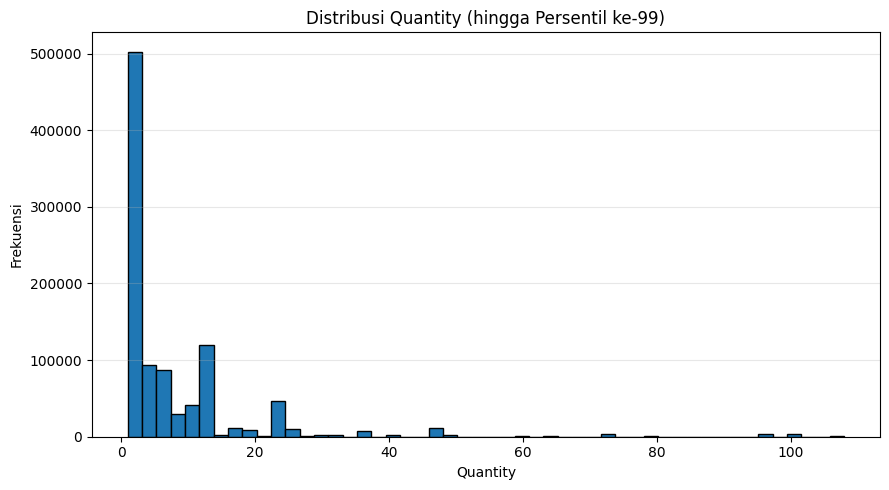

Variabel                  : Quantity
Persentil ke-99 (P99)     : 108.000
Jumlah data asli          : 1,007,914
Jumlah data ditampilkan   : 998,113
Jumlah data di atas P99   : 9,801
Persentase di atas P99    : 0.97%
---------------------------------------------


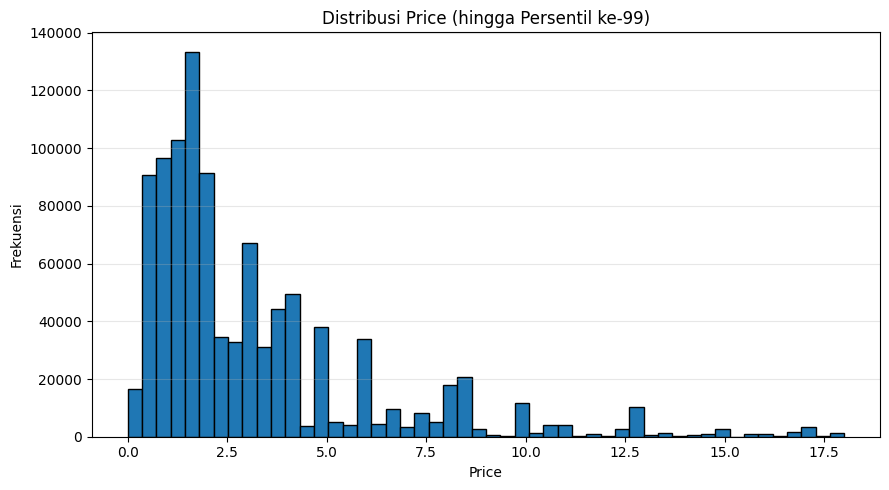

Variabel                  : Price
Persentil ke-99 (P99)     : 18.000
Jumlah data asli          : 1,007,914
Jumlah data ditampilkan   : 998,475
Jumlah data di atas P99   : 9,439
Persentase di atas P99    : 0.94%
---------------------------------------------


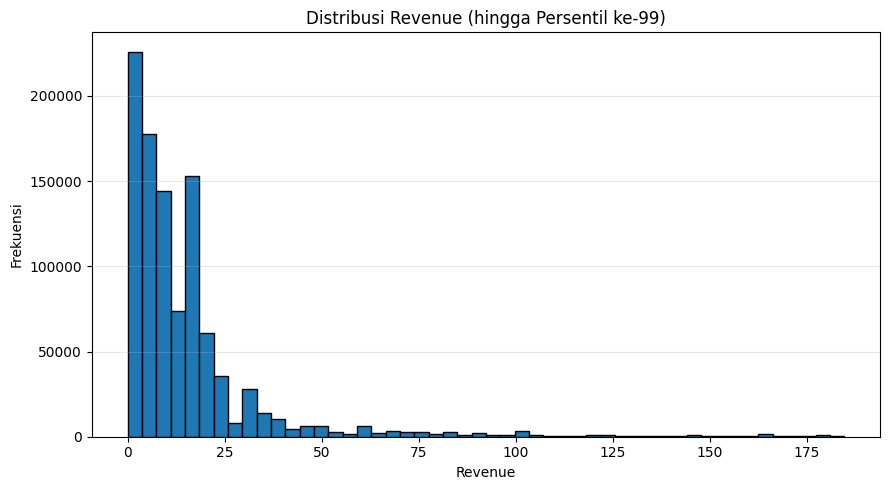

Variabel                  : Revenue
Persentil ke-99 (P99)     : 184.670
Jumlah data asli          : 1,007,914
Jumlah data ditampilkan   : 997,834
Jumlah data di atas P99   : 10,080
Persentase di atas P99    : 1.00%
---------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
for kolom in ["Quantity", "Price", "Revenue"]:
    # Mengambil data yang tidak kosong
    data = df[kolom].dropna()
    # Menghitung persentil ke-99
    batas_99 = data.quantile(0.99)
    # Membatasi data hanya untuk keperluan visualisasi
    data_visual = data[data <= batas_99]
    # Menghitung jumlah data yang tidak ditampilkan pada histogram
    jumlah_dipotong = len(data) - len(data_visual)
    persen_dipotong = (jumlah_dipotong / len(data)) * 100
    # Membuat histogram
    plt.figure(figsize=(9, 5))
    plt.hist(data_visual, bins=50, edgecolor="black")
    plt.title(f"Distribusi {kolom} (hingga Persentil ke-99)")
    plt.xlabel(kolom)
    plt.ylabel("Frekuensi")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
    # Menampilkan ringkasan hasil
    print(f"Variabel                  : {kolom}")
    print(f"Persentil ke-99 (P99)     : {batas_99:.3f}")
    print(f"Jumlah data asli          : {len(data):,}")
    print(f"Jumlah data ditampilkan   : {len(data_visual):,}")
    print(f"Jumlah data di atas P99   : {jumlah_dipotong:,}")
    print(f"Persentase di atas P99    : {persen_dipotong:.2f}%")
    print("-" * 45)

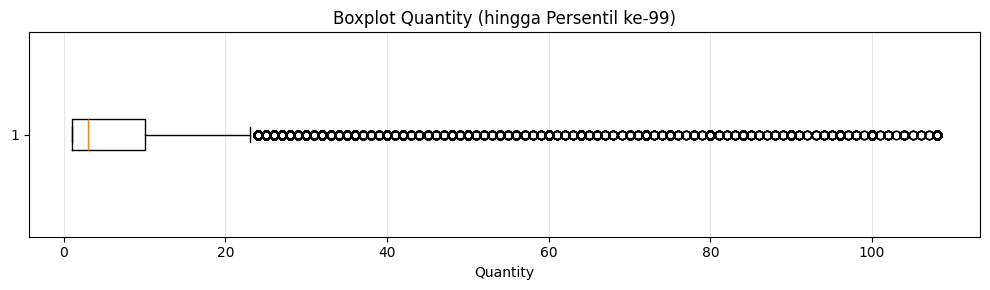

Quantity: batas persentil ke-99 = 108.000


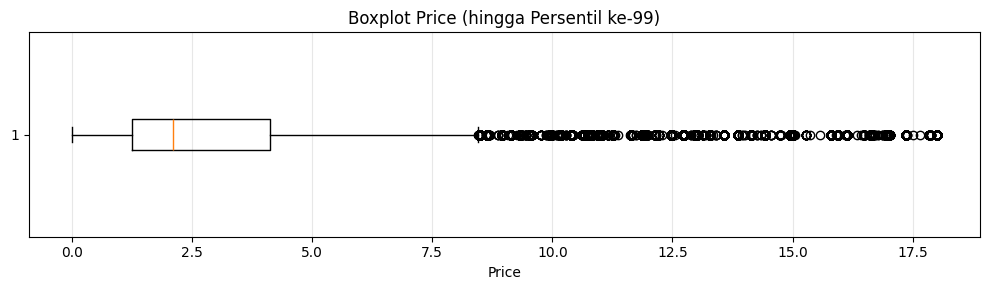

Price: batas persentil ke-99 = 18.000


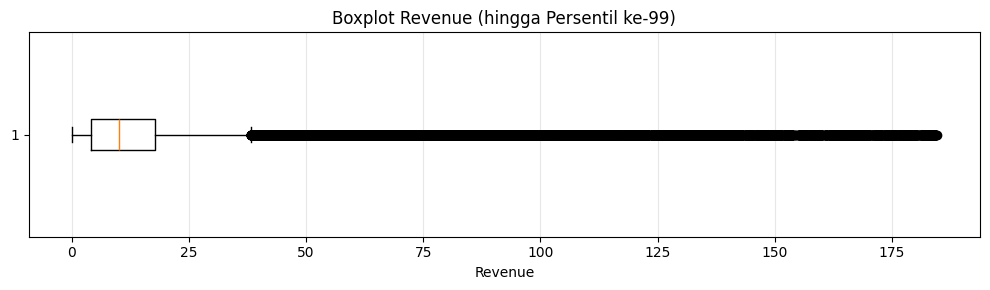

Revenue: batas persentil ke-99 = 184.670


In [ ]:
for kolom in ["Quantity", "Price", "Revenue"]:
    data = df[kolom].dropna()
    batas_99 = data.quantile(0.99)

    plt.figure(figsize=(10, 3))
    plt.boxplot(
        data[data <= batas_99],
        vert=False
    )

    plt.title(f"Boxplot {kolom} (hingga Persentil ke-99)")
    plt.xlabel(kolom)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"{kolom}: batas persentil ke-99 = {batas_99:.3f}")

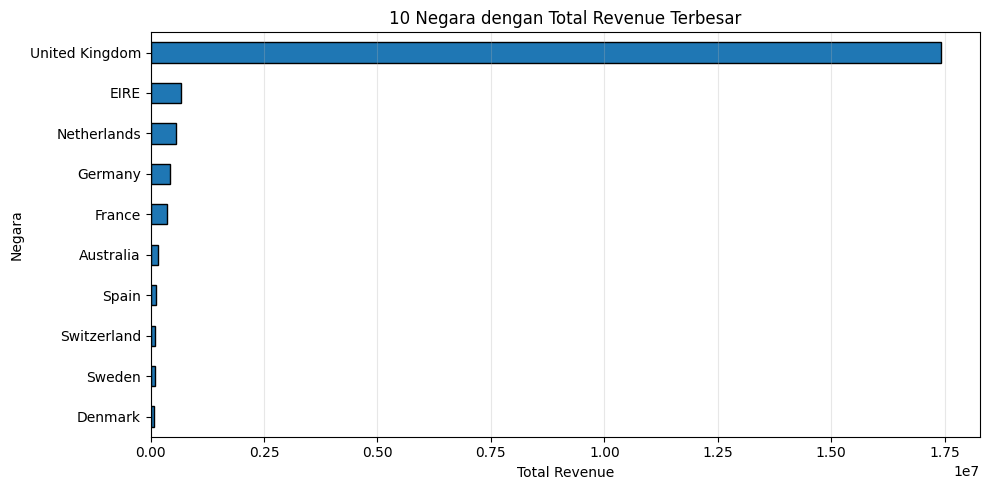

Total Revenue per Negara:


,Revenue
Country,
United Kingdom,1.741057e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


In [ ]:
top_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
top_revenue.sort_values().plot(kind="barh", edgecolor="black")

plt.title("10 Negara dengan Total Revenue Terbesar")
plt.xlabel("Total Revenue")
plt.ylabel("Negara")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total Revenue per Negara:")
display(top_revenue.to_frame())

In [ ]:
# Mengubah InvoiceDate menjadi format tanggal
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Memeriksa rentang tanggal dalam dataset
print("Tanggal paling awal:", df["InvoiceDate"].min())
print("Tanggal paling akhir:", df["InvoiceDate"].max())

Tanggal paling awal: 2009-12-01 07:45:00
Tanggal paling akhir: 2011-12-09 12:50:00


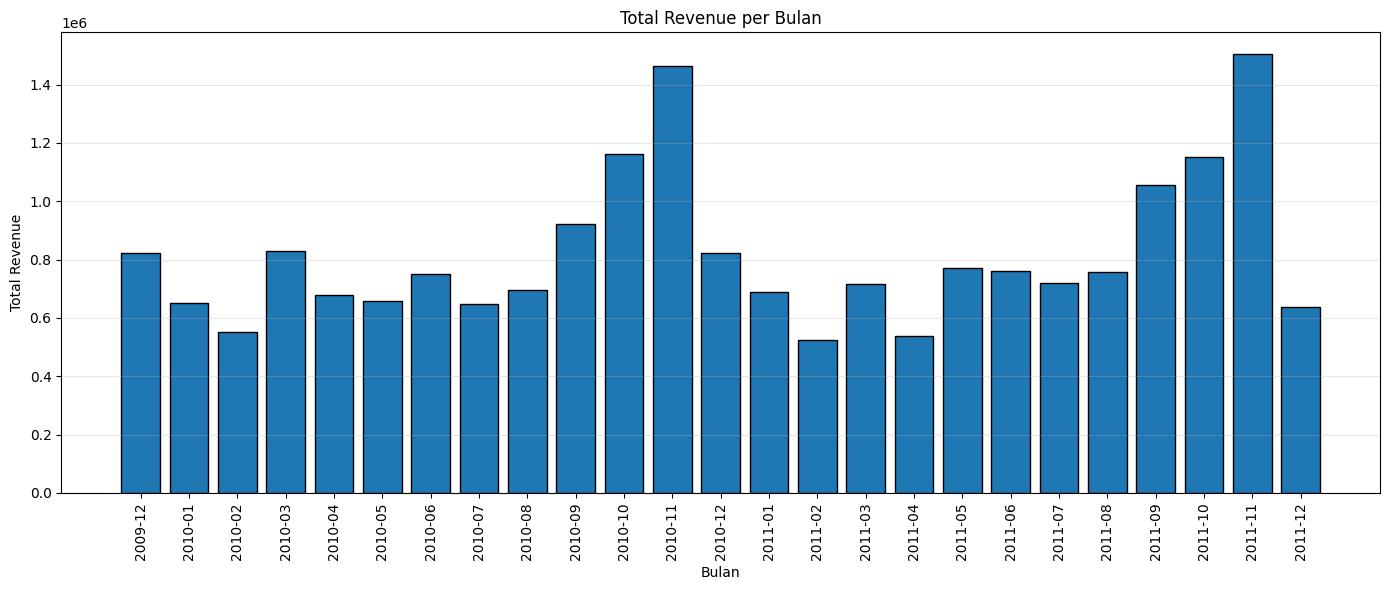

5 bulan pertama:


,Revenue
Bulan,
2009-12,822483.950
2010-01,651155.112
2010-02,551878.296
2010-03,830915.261
2010-04,678875.252


5 bulan terakhir:


,Revenue
Bulan,
2011-08,757841.380
2011-09,1056435.192
2011-10,1151263.730
2011-11,1503866.780
2011-12,637808.330


In [ ]:
# Mengelompokkan Revenue berdasarkan bulan
df["Bulan"] = df["InvoiceDate"].dt.to_period("M")
revenue_bulanan = (
    df.groupby("Bulan")["Revenue"]
    .sum()
    .sort_index())
# Membuat diagram batang
plt.figure(figsize=(14, 6))
plt.bar(
    revenue_bulanan.index.astype(str),
    revenue_bulanan.values,
    edgecolor="black")
plt.title("Total Revenue per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
# Menampilkan 5 bulan pertama dan terakhir
print("5 bulan pertama:")
display(revenue_bulanan.head().to_frame())

print("5 bulan terakhir:")
display(revenue_bulanan.tail().to_frame())

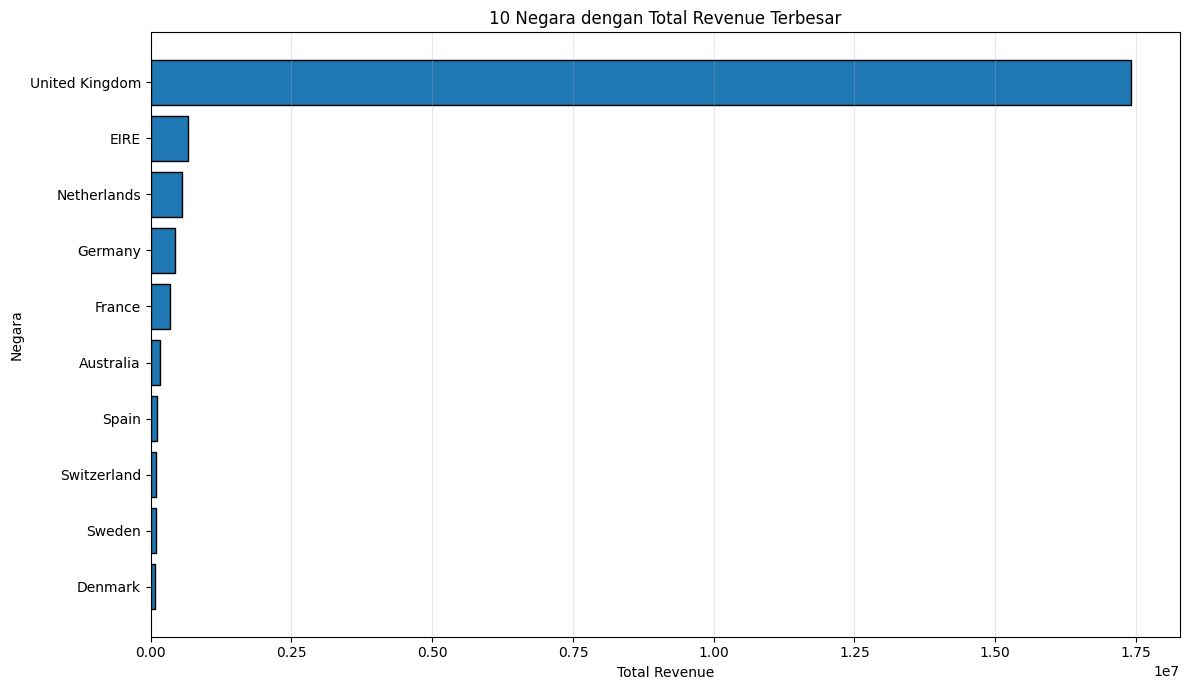

10 negara dengan total Revenue terbesar:


,Total Revenue
Country,
United Kingdom,1.741057e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


In [ ]:

# Mengelompokkan Revenue berdasarkan negara
revenue_negara = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True))
# Membuat diagram batang horizontal
plt.figure(figsize=(12, 7))
plt.barh(
    revenue_negara.index,
    revenue_negara.values,
    edgecolor="black")
plt.title("10 Negara dengan Total Revenue Terbesar")
plt.xlabel("Total Revenue")
plt.ylabel("Negara")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
# Menampilkan tabel 10 negara teratas
print("10 negara dengan total Revenue terbesar:")
display(
    revenue_negara
    .sort_values(ascending=False)
    .to_frame(name="Total Revenue")
)

In [ ]:

# Memeriksa apakah ada nilai nol atau negatif
for kolom in ["Quantity", "Price", "Revenue"]:
    print(
        f"{kolom}:",
        (df[kolom] <= 0).sum(),
        "nilai nol atau negatif"
    )

Quantity: 0 nilai nol atau negatif
Price: 0 nilai nol atau negatif
Revenue: 0 nilai nol atau negatif


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
print(df.shape)
print(df.columns.tolist())

NameError: name 'df' is not defined

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

Saving online_retail_II_clean.csv to online_retail_II_clean.csv
